# 08 · Distributional semantics and word2vec

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-nlp-course/blob/main/notebooks/08_word2vec.ipynb)

*Practical NLP — a hands-on course in classical natural language processing · Notebook 8 of 12*

> "You shall know a word by the company it keeps." — J. R. Firth, 1957

LSA (notebook 07) gave words dense vectors from *document-level* co-occurrence. **word2vec**
(Mikolov et al., 2013) learns dense word vectors from *local context windows*: a small neural network is
trained to predict a word from its neighbours (CBOW) or the neighbours from the word (skip-gram), and the
weights it learns become the word vectors. In this notebook we train word2vec ourselves, fully offline, on
the newsgroup posts with `gensim`, and explore what the vectors have — and have not — learned.

### Learning objectives
By the end of this notebook you will be able to:
1. State the distributional hypothesis and explain why one-hot vectors cannot express word similarity.
2. Generate skip-gram training pairs from a sentence by hand and describe CBOW vs skip-gram.
3. Train a word2vec model with `gensim` and query nearest neighbours, similarities and analogies.
4. Visualise word vectors in 2D with PCA and t-SNE.
5. Judge the quality of embeddings trained on a small corpus, and know when that is not enough.

## 0 · Setup

In [1]:
# Setup — works in Google Colab and locally.
# In Colab: installs missing packages and clones the course repo (for its cached data).
# Locally / in CI: uses the files already in data/ (NLP_OFFLINE=1 forbids any download).
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nltk>=3.9", "scikit-learn", "gensim>=4.3"], check=True)
    if not Path("practical-nlp-course").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-nlp-course.git"], check=True)
    os.chdir("practical-nlp-course/notebooks")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import nlp_course
nlp_course.setup_nltk()

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)
print("Offline mode:", nlp_course.OFFLINE)
print("Cached data:", sorted(p.name for p in (ROOT / "data").iterdir() if p.suffix in {".gz", ".json"}))

Offline mode: True
Cached data: ['20newsgroups_4cat.csv.gz', 'provenance.json', 'sms_spam.csv.gz']


In [2]:
import time
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

## 1 · From one-hot vectors to dense vectors
With one-hot vectors (notebook 03) every word is orthogonal to every other word: the cosine similarity
between *any* two different words is 0.

In [3]:
words = ["rocket", "launch", "pitcher"]
onehot = np.eye(len(words))
print(pd.DataFrame(onehot @ onehot.T, index=words, columns=words))

         rocket  launch  pitcher
rocket      1.0     0.0      0.0
launch      0.0     1.0      0.0
pitcher     0.0     0.0      1.0


The **distributional hypothesis** says that words appearing in similar contexts have similar meanings.
"rocket" and "launch" are surrounded by words like *orbit, NASA, fuel*; "pitcher" by *inning, mound, Red Sox*.
word2vec turns this idea into a training objective and gives every word a dense vector (here 100 numbers)
such that words with similar contexts end up close together.

## 2 · Skip-gram and CBOW
Slide a **window** over the text. For each position the centre word is the *target* and the words within
`window` positions on either side are its *context*.

In [4]:
sentence = "the shuttle will launch the satellite into orbit".split()
window = 2
pairs = []
for i, target in enumerate(sentence):
    for j in range(max(0, i - window), min(len(sentence), i + window + 1)):
        if j != i:
            pairs.append((target, sentence[j]))
print(len(pairs), "skip-gram (target → context) pairs, e.g.:")
for p in pairs[8:16]:
    print("  ", p)

26 skip-gram (target → context) pairs, e.g.:
   ('will', 'the')
   ('launch', 'shuttle')
   ('launch', 'will')
   ('launch', 'the')
   ('launch', 'satellite')
   ('the', 'will')
   ('the', 'launch')
   ('the', 'satellite')


- **Skip-gram** trains a model to predict each context word from the target word: `launch → shuttle`,
  `launch → will`, `launch → the`, `launch → satellite`.
- **CBOW** (continuous bag of words) does the reverse: it averages the context vectors and predicts the
  target: `(shuttle, will, the, satellite) → launch`.

The "network" is tiny: an input embedding matrix (one 100-d row per word), an output matrix, and a dot
product between them. Computing a softmax over the whole vocabulary would be slow, so word2vec uses
**negative sampling**: for each true (target, context) pair it also draws a few random "noise" words and
learns to score the true pair high and the noise pairs low. After training, the input embedding matrix
*is* the set of word vectors.

Rules of thumb: skip-gram is slower but tends to represent rare words better; CBOW is faster and smoother
for frequent words.

## 3 · The training corpus
word2vec needs as much running text as possible, and it learns from word order, so we keep stopwords
(they are context too) and do not lemmatise. No labels are used, so we train on **all** 3,729 posts.

In [5]:
df = nlp_course.load_newsgroups()
sentences = [nlp_course.preprocess(t, remove_stopwords=False, normalize=None) for t in df["text"]]
n_tokens = sum(len(s) for s in sentences)
print(f"{len(sentences):,} posts, {n_tokens:,} tokens, {len(set(w for s in sentences for w in s)):,} distinct words")
print(sentences[0][:25])

3,729 posts, 668,644 tokens, 29,433 distinct words
['yes', 'long', 'before', 'star', 'trek', 'before', 'einstein', 'in', 'fact', 'vulcan', 'as', 'planet', 'inside', 'mercury', 'was', 'hypothesized', 'to', 'explain', 'perturbation', 'of', 'mercury', 'orbit', 'that', 'could', 'not']


About 670 thousand tokens. For comparison, the vectors Google released in 2013 were trained on about
100 *billion* tokens of news — roughly 150,000 times more text. Keep that in mind when judging the results.

## 4 · Training word2vec with gensim
Key parameters: `vector_size` (dimensions), `window` (context size), `min_count` (ignore rarer words),
`sg=1` for skip-gram or `sg=0` for CBOW, `negative` (noise words per pair, default 5) and `epochs`
(passes over the corpus; small corpora need more). `workers=1` plus a fixed `seed` makes training
reproducible.

In [6]:
params = dict(vector_size=100, window=5, min_count=5, negative=5, epochs=20, workers=1, seed=0)
t0 = time.time()
sg = Word2Vec(sentences, sg=1, **params)
t_sg = time.time() - t0
t0 = time.time()
cbow = Word2Vec(sentences, sg=0, **params)
t_cbow = time.time() - t0
print(f"vocabulary: {len(sg.wv):,} words (min_count=5)")
print(f"skip-gram trained in {t_sg:.0f} s, CBOW in {t_cbow:.0f} s")
print("vector for 'orbit' (first 8 of 100 numbers):", sg.wv["orbit"][:8].round(3))

vocabulary: 9,445 words (min_count=5)
skip-gram trained in 33 s, CBOW in 8 s
vector for 'orbit' (first 8 of 100 numbers): [ 0.132 -0.306  0.001 -0.147  0.315  0.362 -0.433  0.198]


## 5 · Nearest neighbours
`most_similar` ranks the vocabulary by cosine similarity to a word's vector.

In [7]:
probe = ["orbit", "shuttle", "pitcher", "jpeg", "software", "president", "tax"]
def neighbours(model, word, n=6):
    return ", ".join(w for w, _ in model.wv.most_similar(word, topn=n))
pd.DataFrame({"skip-gram": [neighbours(sg, w) for w in probe],
              "CBOW": [neighbours(cbow, w) for w in probe]}, index=probe)

,skip-gram,CBOW
orbit,"orbits, insertion, polar, hiten, maneuvering, hagoromo","comet, pluto, fuel, jupiter, atmosphere, hst"
shuttle,"ksc, spacelab, jsc, srb, shuttles, sts","reboost, launch, station, centaur, mission, servicing"
pitcher,"morris, dh, infield, lineup, maldonado, berryhill","hitter, player, clemens, catcher, morris, bonds"
jpeg,"lossless, implementations, gif, jfif, decoder, lzw","jfif, gif, tiff, file, format, viewer"
software,"imdisp, wingert, canned, macintosh, handmade, mgif","hardware, application, product, macintosh, grass, platform"
president,"havel, yeltsin, stephanopoulos, advisors, rivlin, bentsen","administration, secretary, congress, attorney, dole, senator"
tax,"income, vat, taxes, concrete, federal, revenue","income, federal, taxes, vat, raise, government"


Neither model was told anything about meaning, yet the neighbours are clearly topical. They are
also *noisy*: with this little text, skip-gram's neighbours are dominated by rare, specific words (player
surnames for *pitcher*, mission names such as *hiten* for *orbit*) and a few surprises such as
*concrete* next to *tax*. On this small corpus CBOW gives the more "dictionary-like" neighbours
(*pitcher → hitter, player, catcher*; *software → hardware, application*).

### Similarity scores and the odd one out

In [8]:
for a, b in [("rocket", "launch"), ("rocket", "pitcher"), ("jpeg", "gif"), ("tax", "income"), ("tax", "orbit")]:
    print(f"cos({a}, {b}):  skip-gram {sg.wv.similarity(a, b):+.3f}   CBOW {cbow.wv.similarity(a, b):+.3f}")
for group in [["orbit", "shuttle", "launch", "pitcher"], ["jpeg", "gif", "tiff", "senate"]]:
    print(f"odd one out in {group}: {cbow.wv.doesnt_match(group)}")

cos(rocket, launch):  skip-gram +0.482   CBOW +0.596
cos(rocket, pitcher):  skip-gram +0.151   CBOW +0.001
cos(jpeg, gif):  skip-gram +0.595   CBOW +0.621
cos(tax, income):  skip-gram +0.741   CBOW +0.729
cos(tax, orbit):  skip-gram +0.134   CBOW -0.013
odd one out in ['orbit', 'shuttle', 'launch', 'pitcher']: pitcher
odd one out in ['jpeg', 'gif', 'tiff', 'senate']: senate


## 6 · Analogies — when do they emerge?
The famous result *king − man + woman ≈ queen* is computed with vector arithmetic:
`most_similar(positive=[a, c], negative=[b])` finds the word closest to $\vec a - \vec b + \vec c$.
Let us try a few on our models.

In [9]:
analogies = [("went", "go", "come"),      # past tense
             ("better", "good", "bad"),     # comparative
             ("years", "year", "day"),      # plural
             ("images", "image", "pitcher"),  # plural, mixing two topics
             ("mars", "planet", "moon"),
             ("clinton", "president", "pitcher")]
rows = []
for a, b, c in analogies:
    rows.append({"query": f"{a} − {b} + {c}",
                 "skip-gram top 3": ", ".join(w for w, _ in sg.wv.most_similar(positive=[a, c], negative=[b], topn=3)),
                 "CBOW top 3": ", ".join(w for w, _ in cbow.wv.most_similar(positive=[a, c], negative=[b], topn=3))})
pd.DataFrame(rows).set_index("query")

,skip-gram top 3,CBOW top 3
query,,
went − go + come,"came, wasn, invasion","came, showed, broke"
better − good + bad,"bones, slower, ml","worse, less, bigger"
years − year + day,"hours, centuries, days","weeks, days, months"
images − image + pitcher,"bunt, odds, bullpen","hitters, pitchers, pitch"
mars − planet + moon,"observer, cola, expeditions","lunar, observer, ulysses"
clinton − president + pitcher,"morris, rushed, rbi","catcher, bonds, ab"


Honest assessment: a few **grammatical** analogies work — *went − go + come → came* (both models),
*better − good + bad → worse* and *years − year + day → weeks, days* (CBOW), and CBOW even ranks *pitchers*
second for *images − image + pitcher*. The **semantic** ones fail: the last two queries return words from the right
topic but not the right answer. Analogies need many examples of each relation; grammatical patterns
(plural, past tense) occur constantly, semantic relations are far rarer in 670k tokens. The well-known
analogy results come from models trained on billions of words.

## 7 · Visualising the embedding space
Pick a handful of words from each newsgroup and project their 100-d CBOW vectors to 2D with **PCA**
(linear) and **t-SNE** (non-linear, preserves local neighbourhoods).

missing from vocabulary:

 []


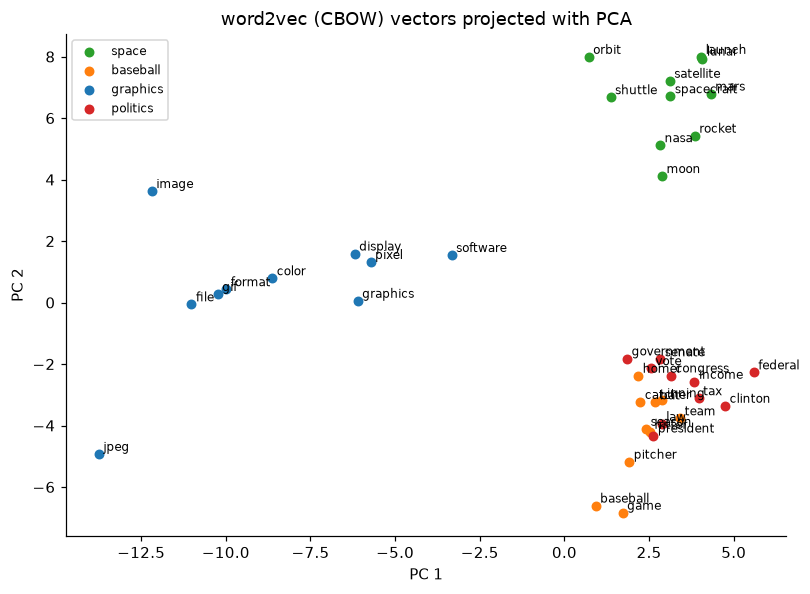

In [10]:
groups = {
    "space": ["orbit", "shuttle", "launch", "nasa", "moon", "mars", "satellite", "rocket", "lunar", "spacecraft"],
    "baseball": ["pitcher", "hitter", "inning", "season", "game", "team", "catcher", "baseball", "homer", "bat"],
    "graphics": ["image", "jpeg", "gif", "file", "format", "software", "color", "pixel", "display", "graphics"],
    "politics": ["president", "government", "tax", "congress", "clinton", "law", "senate", "federal", "income", "vote"],
}
gcol = {"space": "tab:green", "baseball": "tab:orange", "graphics": "tab:blue", "politics": "tab:red"}
plot_words = [w for ws in groups.values() for w in ws]
missing = [w for w in plot_words if w not in cbow.wv]
print("missing from vocabulary:", missing)
V = np.array([cbow.wv[w] for w in plot_words])
P = PCA(n_components=2, random_state=0).fit_transform(V)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
i = 0
for g, ws in groups.items():
    ax.scatter(P[i:i + len(ws), 0], P[i:i + len(ws), 1], color=gcol[g], label=g, s=30)
    for k, w in enumerate(ws):
        ax.annotate(w, P[i + k], fontsize=8, xytext=(3, 2), textcoords="offset points")
    i += len(ws)
ax.set_title("word2vec (CBOW) vectors projected with PCA"); ax.legend(fontsize=8)
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
plt.tight_layout(); plt.savefig(DOCS / "08_word2vec_pca.png", bbox_inches="tight"); plt.show()

The first two principal components already pull **space** words (top) and **graphics** words (left) away
from the rest, but **baseball** and **politics** words overlap in this linear 2D view — only the most
typical baseball words (*pitcher, baseball, game*) sit apart at the bottom. Two directions out of 100 cannot
show everything. t-SNE, which tries to keep each word's nearest neighbours close, does better. Here it is on
the 400 most frequent non-stopword words:

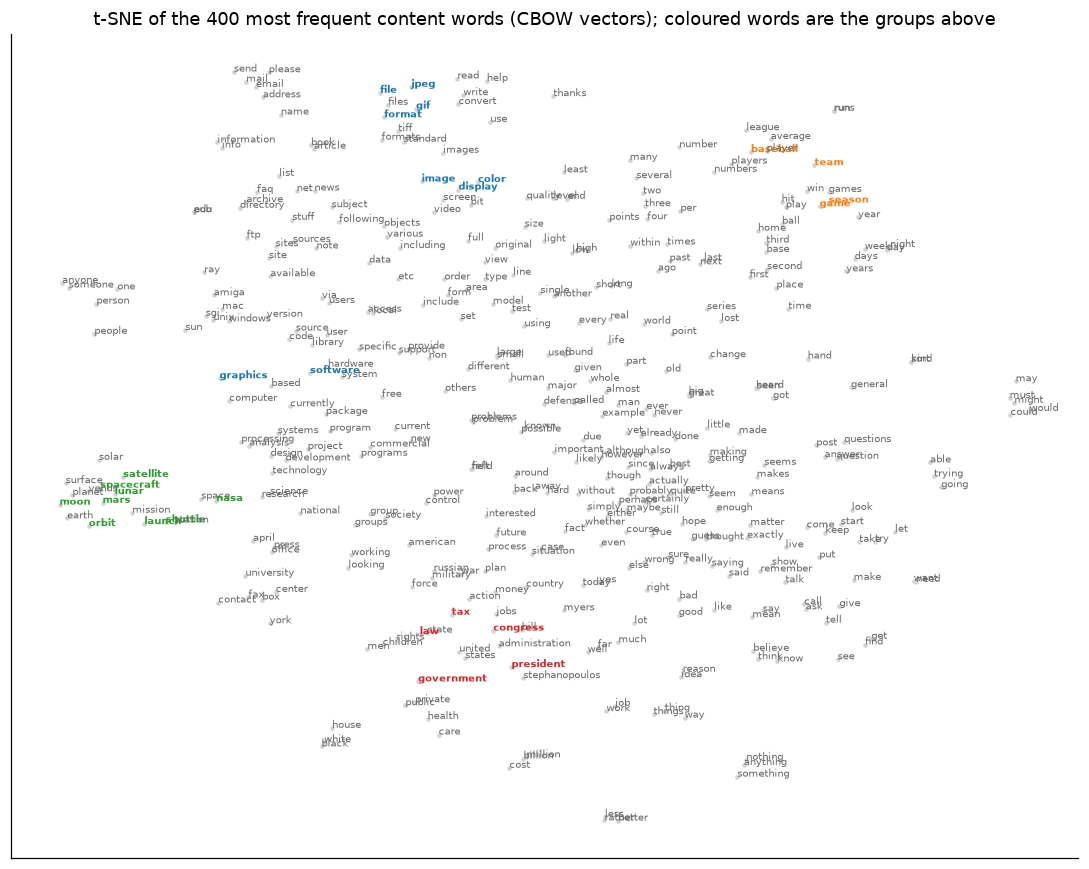

In [11]:
from collections import Counter
stops = nlp_course._stopwords()
freq = Counter(w for s in sentences for w in s if w not in stops and len(w) > 2)
top_words = [w for w, _ in freq.most_common(400)]
tsne = TSNE(n_components=2, perplexity=20, init="pca", random_state=0)
T = tsne.fit_transform(np.array([cbow.wv[w] for w in top_words]))

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(T[:, 0], T[:, 1], s=4, color="lightgray")
lookup = {w: g for g, ws in groups.items() for w in ws}
for (x, y), w in zip(T, top_words):
    ax.annotate(w, (x, y), fontsize=6.5, color=gcol.get(lookup.get(w), "dimgray"),
                fontweight="bold" if w in lookup else "normal")
ax.set_title("t-SNE of the 400 most frequent content words (CBOW vectors); coloured words are the groups above")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(DOCS / "08_word2vec_tsne.png", bbox_inches="tight"); plt.show()

Now all four groups get their own neighbourhood: space terms (left), file and image formats (top),
baseball terms (top right) and political vocabulary (bottom). Generic words also cluster by role: number
words (*two, three, four*), modal verbs (*may, must, could, would*) and e-mail vocabulary (*send, mail,
address*).

## 8 · Limits of word2vec (and of a small corpus)
- **One vector per word type**: *bat* (baseball) and *bat* (animal) share a vector; context-dependent
  meanings need contextual models (see the companion repo
  [attention-explained](https://github.com/hentablihamza/attention-explained)).
- **Out-of-vocabulary words** have no vector at all — e.g. any word seen fewer than 5 times here.
- **Data hunger**: with ~670k tokens the neighbours are topical but noisy and most analogies fail.
  Large pretrained vectors (next notebook) fix much of this by learning from billions of words.
- Results depend on hyper-parameters (window, dimensions, epochs) — Exercise 1.

In [12]:
for w in ["quarterback", "smartphone", "selfie"]:
    print(f"{w!r} in vocabulary? {w in cbow.wv}")

'quarterback' in vocabulary? False
'smartphone' in vocabulary? False
'selfie' in vocabulary? False


## Exercises
**Exercise 1.** Train CBOW with `window=2` and with `window=10` (same other parameters, `epochs=10` to save
time) and compare the neighbours of `"shuttle"` and `"president"`. Which window gives more topical and which
more "same-role" neighbours?

In [13]:
# your code here

<details>
<summary><b>Show solution</b></summary>

With window=2, the neighbours of shuttle are things that could take its place in a sentence (station, vehicle, mission, flight); with window=10 they are words from the same topic (launch, servicing, hst, dock, pad). Small windows favour similar role, large windows favour topical relatedness.

```python
for win in [2, 10]:
    m = Word2Vec(sentences, sg=0, **{**params, "window": win, "epochs": 10})
    for w in ["shuttle", "president"]:
        print(f"window={win:>2}  {w:>9}: {neighbours(m, w)}")
```
</details>

In [14]:
for win in [2, 10]:
    m = Word2Vec(sentences, sg=0, **{**params, "window": win, "epochs": 10})
    for w in ["shuttle", "president"]:
        print(f"window={win:>2}  {w:>9}: {neighbours(m, w)}")

window= 2    shuttle: station, vehicle, mission, flight, ssf, savings
window= 2  president: clinton, limbaugh, fbi, administration, george, stephanopoulos


window=10    shuttle: launch, mission, servicing, hst, dock, pad
window=10  president: administration, stephanopoulos, dole, mr, secretary, senator


**Exercise 2.** Write `odd_one_out(words)` that returns the word with the lowest mean cosine
similarity to the others — without using `doesnt_match` — and check it agrees with gensim on
`["jpeg", "gif", "tiff", "senate"]` and `["inning", "pitcher", "homer", "orbit"]`.

In [15]:
# your code here

<details>
<summary><b>Show solution</b></summary>

gensim's doesnt_match compares each word with the mean of the normalised vectors; the mean pairwise similarity gives the same answer here.

```python
def odd_one_out(words, model=cbow):
    V = np.array([model.wv[w] / np.linalg.norm(model.wv[w]) for w in words])
    S = V @ V.T
    mean_sim = (S.sum(axis=1) - 1) / (len(words) - 1)   # exclude self-similarity
    return words[int(np.argmin(mean_sim))]
for g in [["jpeg", "gif", "tiff", "senate"], ["inning", "pitcher", "homer", "orbit"]]:
    print(g, "->", odd_one_out(g), "| gensim:", cbow.wv.doesnt_match(g))
```
</details>

In [16]:
def odd_one_out(words, model=cbow):
    V = np.array([model.wv[w] / np.linalg.norm(model.wv[w]) for w in words])
    S = V @ V.T
    mean_sim = (S.sum(axis=1) - 1) / (len(words) - 1)   # exclude self-similarity
    return words[int(np.argmin(mean_sim))]
for g in [["jpeg", "gif", "tiff", "senate"], ["inning", "pitcher", "homer", "orbit"]]:
    print(g, "->", odd_one_out(g), "| gensim:", cbow.wv.doesnt_match(g))

['jpeg', 'gif', 'tiff', 'senate'] -> senate | gensim: senate
['inning', 'pitcher', 'homer', 'orbit'] -> orbit | gensim: orbit


**Exercise 3.** Turn word vectors into **document vectors** by averaging the CBOW vectors of a post's
in-vocabulary words (skip stopwords). Using the train/test split, compute precision@10 for retrieving
same-topic training posts with cosine similarity, as in notebook 06. How does it compare with TF-IDF (0.744
in notebook 06)?

In [17]:
# your code here

<details>
<summary><b>Show solution</b></summary>

Averaged 100-d word2vec vectors reach precision@10 = 0.816, better than TF-IDF (0.744) with a far more compact representation. (The word vectors saw the test posts' text during training — not their labels — so this is slightly optimistic.)

```python
from sklearn.metrics.pairwise import cosine_similarity
def doc_vector(tokens, model=cbow):
    vecs = [model.wv[w] for w in tokens if w in model.wv and w not in stops]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)
D = np.array([doc_vector(s) for s in sentences])
is_train = (df["subset"] == "train").to_numpy()
y = df["category"].to_numpy()
ok = np.abs(D).sum(axis=1) > 0
Dtr, ytr = D[is_train], y[is_train]
Dte, yte = D[~is_train & ok], y[~is_train & ok]
nn = np.argsort(-cosine_similarity(Dte, Dtr), axis=1)[:, :10]
print(f"averaged word2vec, {ok[~is_train].sum():,} test posts: precision@10 = {(ytr[nn] == yte[:, None]).mean():.3f}")
```
</details>

In [18]:
from sklearn.metrics.pairwise import cosine_similarity
def doc_vector(tokens, model=cbow):
    vecs = [model.wv[w] for w in tokens if w in model.wv and w not in stops]
    return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)
D = np.array([doc_vector(s) for s in sentences])
is_train = (df["subset"] == "train").to_numpy()
y = df["category"].to_numpy()
ok = np.abs(D).sum(axis=1) > 0
Dtr, ytr = D[is_train], y[is_train]
Dte, yte = D[~is_train & ok], y[~is_train & ok]
nn = np.argsort(-cosine_similarity(Dte, Dtr), axis=1)[:, :10]
print(f"averaged word2vec, {ok[~is_train].sum():,} test posts: precision@10 = {(ytr[nn] == yte[:, None]).mean():.3f}")

averaged word2vec, 1,440 test posts: precision@10 = 0.816


## Summary
- The distributional hypothesis: words in similar contexts have similar meanings.
- word2vec learns dense vectors by predicting context words (skip-gram) or the centre word (CBOW), with negative sampling.
- Trained offline on ~670k tokens of newsgroup posts, the vectors capture topics clearly; on this small corpus CBOW gives cleaner neighbours than skip-gram.
- Some grammatical analogies emerge (*went − go + come → came*), semantic ones mostly do not: small corpora give noisy embeddings.
- Embeddings have one vector per word and no vector for unseen words.

**Next:** [09 · GloVe and pretrained embeddings](09_glove_and_pretrained.ipynb).